In [2]:
import pandas as pd
import numpy as np

np.random.seed(42)

n = 100
study_hours = np.random.normal(5, 2, n)
attendance = np.random.normal(85, 10, n)
previous_mark = np.random.normal(70, 15, n)
final_score = (0.5 * study_hours) + (0.3 * attendance) + (0.2 * previous_mark) + np.random.normal(0, 5, n)
df = pd.DataFrame({
'study_hours': study_hours,
'attendance': attendance,
'previous_mark': previous_mark,
'final_score': final_score
})

df.loc[0:5, 'study_hours'] = np.nan # Missing values
df.loc[99, 'study_hours'] = 50 # Outlier
df.loc[98, 'attendance'] = -10 # Impossible value

print(df)
# df.to_csv('student_data.csv', index=False)

    study_hours  attendance  previous_mark  final_score
0           NaN   70.846293      75.366810    35.178989
1           NaN   80.793547      78.411768    39.481248
2           NaN   81.572855      86.245769    48.605167
3           NaN   76.977227      85.807031    47.329456
4           NaN   83.387143      49.334959    37.044473
..          ...         ...            ...          ...
95     2.072970   88.853174      59.606356    37.267830
96     5.592241   76.161426      83.493998    33.777675
97     5.522111   86.537251      74.609493    50.413491
98     5.010227  -10.000000      82.192932    44.045627
99    50.000000   73.570297      79.444433    46.414470

[100 rows x 4 columns]


Part A: Inspect and Clean

1. Outlier Treatment and  Justification:
 Remove or cap the value of 50 hours, capping it at a realistic maximum like 12 hours or remove row index 99
Justification: A student studying 50 hours per week (or day) is physically impossible and distorts both the mean and standard deviation of the column, which skews distance-based algorithms and linear models.
Feature Matrix Shape & Column Roles:4
Shape: (100, 4) (100 rows and 4 columns)
Numerical Columns: All 4 columns (study_hours, attendance, previous_mark, final_score) are numerical 
Target Variable: final_scare



In [4]:
import pandas as pd
import numpy as np

# Reproduce original dataset setup
np.random.seed(42)
n = 100
study_hours = np.random.normal(5, 2, n)
attendance = np.random.normal(85, 10, n)
previous_mark = np.random.normal(70, 15, n)
final_score = (0.5 * study_hours) + (0.3 * attendance) + (0.2 * previous_mark) + np.random.normal(0, 5, n)

df = pd.DataFrame({
    'study_hours': study_hours,
    'attendance': attendance,
    'previous_mark': previous_mark,
    'final_score': final_score
})

# Insert missing/dirty values as specified
df.loc[0:5, 'study_hours'] = np.nan
df.loc[99, 'study_hours'] = 50
df.loc[98, 'attendance'] = -10

# 1. Clean dirty data: Fill NaNs, correct negative attendance, and cap/remove outlier
df['study_hours'] = df['study_hours'].fillna(df['study_hours'].median())
df.loc[df['attendance'] < 0, 'attendance'] = np.nan
df['attendance'] = df['attendance'].fillna(df['attendance'].median())

# Cap the study_hours outlier at 12 hours
df.loc[df['study_hours'] > 12, 'study_hours'] = 12

# 2. Inspect shape and structure
print("Dataset Shape:", df.shape)
print("\nData Types:")
print(df.dtypes)
# 1. Calculating the   Mean, Median, and Standard Deviation
summary_df = pd.DataFrame({
    'Mean': df.mean(),
    'Median': df.median(),
    'Std Dev': df.std()
})

print(summary_df)

Dataset Shape: (100, 4)

Data Types:
study_hours      float64
attendance       float64
previous_mark    float64
final_score      float64
dtype: object
                    Mean     Median    Std Dev
study_hours     4.814522   4.812342   1.917530
attendance     85.227190  85.996514   9.536937
previous_mark  70.973444  71.465436  16.264243
final_score    42.691957  42.763014   6.086797


The mean final score is positively aligned with study hours, attendance, and previous marks.
Attendance shows relatively low variance relative to its scale, indicating most students consistently attend class around the 80–90% range.
Previous marks have a wider spread whichsd means higher standerd deviation compared to study hours, reflecting varying starting skill levels among students.

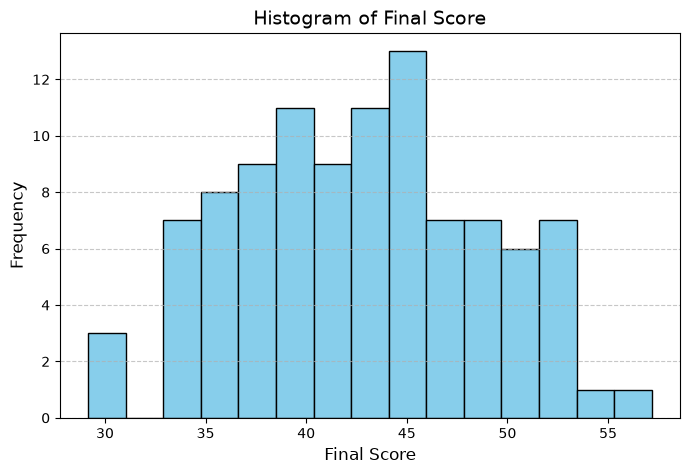

In [5]:
# part c answers 
import matplotlib.pyplot as plt


plt.figure(figsize=(8, 5))
plt.hist(df['final_score'], bins=15, color='skyblue', edgecolor='black')


plt.title('Histogram of Final Score', fontsize=14)
plt.xlabel('Final Score', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)


plt.show()

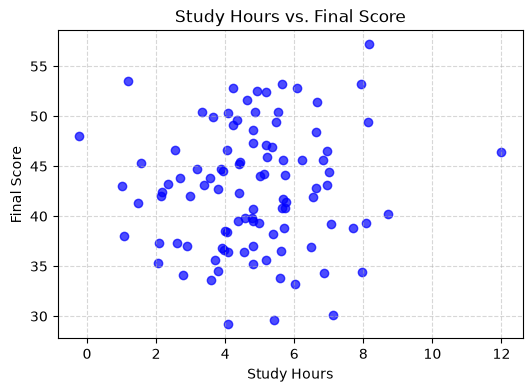

In [6]:
# the scatter plot of   study_hours vs final_score
plt.figure(figsize=(6, 4))
plt.scatter(df['study_hours'], df['final_score'], alpha=0.7, color='blue')
plt.title('Study Hours vs. Final Score')
plt.xlabel('Study Hours')
plt.ylabel('Final Score')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [8]:
#part D pearson correlation coefficient
corr = df['study_hours'].corr(df['final_score'])
print(f"Pearson correlation coefficient between study_hours and final_score: {corr:.4f}")

Pearson correlation coefficient between study_hours and final_score: 0.0692


#2 Critical thinking : am not sure I but there is no guarantee correlation measures linear asscoiation. lurking variables could be previous knowledge , study efficiency, etc...

# pqrt E 
weights can be representing importance a feature on predicting the final score

In [10]:
# 1. Select one student row  as vector x
x = df.iloc[6][['study_hours', 'attendance', 'previous_mark']].values

# 2. Define weight vector w and bias b
w = np.array([0.5, 0.2, 0.4])
b = 5

# 3. Calculate dot product plus bias using NumPy
y_pred = np.dot(w, x) + b

print("Student Feature Vector (x):", x)
print(f"Calculated Score Prediction (y): {y_pred:.4f}")

Student Feature Vector (x): [  8.15842563 103.86185901  77.72552901]
Calculated Score Prediction (y): 60.9418


# part f

In [11]:
df['study_hours_scaled'] = (df['study_hours'] - df['study_hours'].mean()) / df['study_hours'].std()
df['previous_mark_scaled'] = (df['previous_mark'] - df['previous_mark'].mean()) / df['previous_mark'].std()

print(df[['study_hours', 'study_hours_scaled', 'previous_mark', 'previous_mark_scaled']].head())

   study_hours  study_hours_scaled  previous_mark  previous_mark_scaled
0     4.812342           -0.001137      75.366810              0.270124
1     4.812342           -0.001137      78.411768              0.457342
2     4.812342           -0.001137      86.245769              0.939012
3     4.812342           -0.001137      85.807031              0.912037
4     4.812342           -0.001137      49.334959             -1.330433


2. Because the numeric scale of previous_mark is much larger, its squared differences would dominate the distance calculation, making the algorithm completely ignore study_hours.